In [53]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from pathlib import Path
import pandas as pd
import seaborn as sns
import numpy as np
%load_ext autoreload
%autoreload 2
from fwh_analysis import FWHDataset, FWHPlotter


def fft(dataset, col='P_obs', title="FFT Spectrum", max_freq=None, auto_scale=True):
    if type(dataset) == pd.DataFrame:
        time = dataset['Time'].values
        pressure = dataset[col].values
    elif type(dataset) == FWHDataset:
        time = dataset.data['Time'].values
        pressure = dataset.data[col].values
    
    dt = time[1] - time[0]
    N = len(time)
    
    freqs = np.fft.rfftfreq(N, d=dt)
    fft_complex = np.fft.rfft(pressure)
    
    amplitude = 2.0 / N * np.abs(fft_complex)
    amplitude[0] = amplitude[0] / 2
    phases = np.angle(fft_complex)
    
    if auto_scale and max_freq is None:
        max_amp = np.max(amplitude)
        threshold = max(0.01 * max_amp, 1e-3) 
        
        significant_indices = np.where(amplitude > threshold)[0]
        
        if len(significant_indices) > 0:
            highest_significant_freq = freqs[significant_indices[-1]]
            max_freq = min(highest_significant_freq * 1.15, freqs[-1])
        else:
            max_freq = freqs[-1]  # Fallback if flatline

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(freqs, amplitude, linestyle='-', color='b', markersize=4)
    
    ax.set_title(title, weight='bold')
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Amplitude (Pa)')
    ax.grid(True, linestyle='--', alpha=0.6)
    
    if max_freq:
        ax.set_xlim(left=0, right=max_freq)
        
    plt.tight_layout()
    plt.show()
    
    return freqs, amplitude, phases

def dft(t, p, f_1bpf, num_harmonics=10):
    if type(t) == pd.core.series.Series:
        T_period = t.iloc[-1] - t.iloc[0]
    elif type(t) == list:
        T_period = t[-1] - t[0]
    freqs = np.zeros(num_harmonics)
    amps = np.zeros(num_harmonics)
    phases = np.zeros(num_harmonics)

    for n in range(1, num_harmonics + 1):
        freqs[n-1] = n * f_1bpf
        omega_n = 2 * np.pi * freqs[n-1]

        real = np.trapezoid(p * np.cos(omega_n * t), t) * (2.0 / T_period)
        imag = np.trapezoid(p * np.sin(omega_n * t), t) * (2.0 / T_period)

        amps[n-1] = np.sqrt(real ** 2 + imag **2)
        phases[n-1] = np.arctan2(-imag, real)

    return freqs, amps, phases

def dft_spatial(theta_rad, p_theta, num_modes):
    theta_full = np.append(theta_rad, 2 * np.pi)
    p_full = np.append(p_theta, p_theta[0])
    
    modes = np.arange(1, num_modes + 1)
    amps = np.zeros(num_modes)
    phases = np.zeros(num_modes)

    for i, m, in enumerate(modes):
        real = np.trapezoid(p_full * np.cos(m * theta_full), theta_full) / np.pi
        imag = np.trapezoid(p_full * np.sin(m * theta_full), theta_full) / np.pi

        amps[i] = np.sqrt(real **2 + imag **2)
        phases[i] = np.arctan2(-imag, real)

    return modes, amps, phases

def dft_plot(freqs, amps, analysis='temporal'):
    fig, ax = plt.subplots(figsize=(10,5))
    markerline, stemlines, baseline = ax.stem(freqs, amps, basefmt=' ')
    plt.setp(markerline, marker='o', color='red', markersize=6)
    plt.setp(stemlines, color='black', ls='--', linewidth=1.2)

    for x, y in zip(freqs, amps):
        y_offset = max(amps) * 0.05
        ax.text(x, y + y_offset, f"{y:.2f}", ha='center', va='bottom', fontsize=9)

    if analysis == 'tempooral':
        ax.set_xlabel('Frequency (Hz)', fontweight='bold')
        ax.set_title(f"DFT Extraction ({len(freqs)}) Harmonics, 1BPF = {freqs[0]}")
    elif analysis == 'spatial':
        ax.set_xlabel('Modes', fontweight='bold')
        ax.set_title(f'DFT Extraction of Spatial Periodicity')

    ax.set_ylabel('Amplitdue (Pa)', fontweight='bold')
    
    ax.set_ylim(0, max(amps) * 1.2)
    ax.set_xticks(freqs)
    plt.xticks(rotation=45)
    ax.grid(True, ls=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


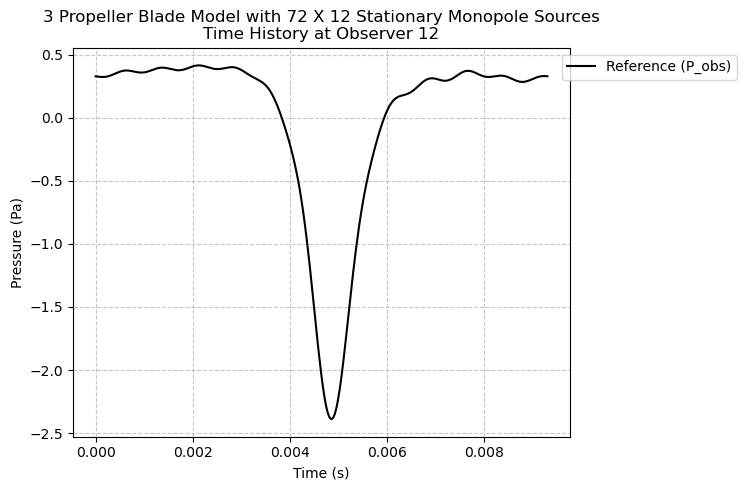

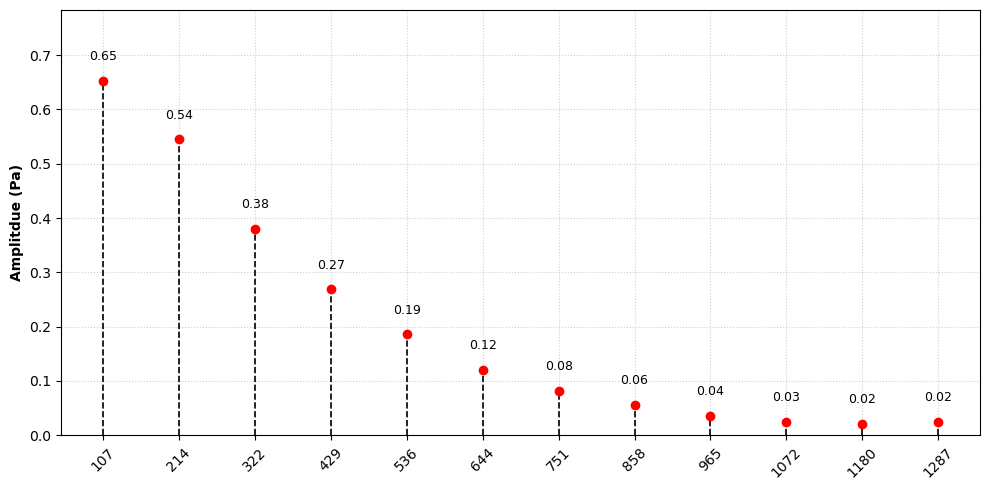

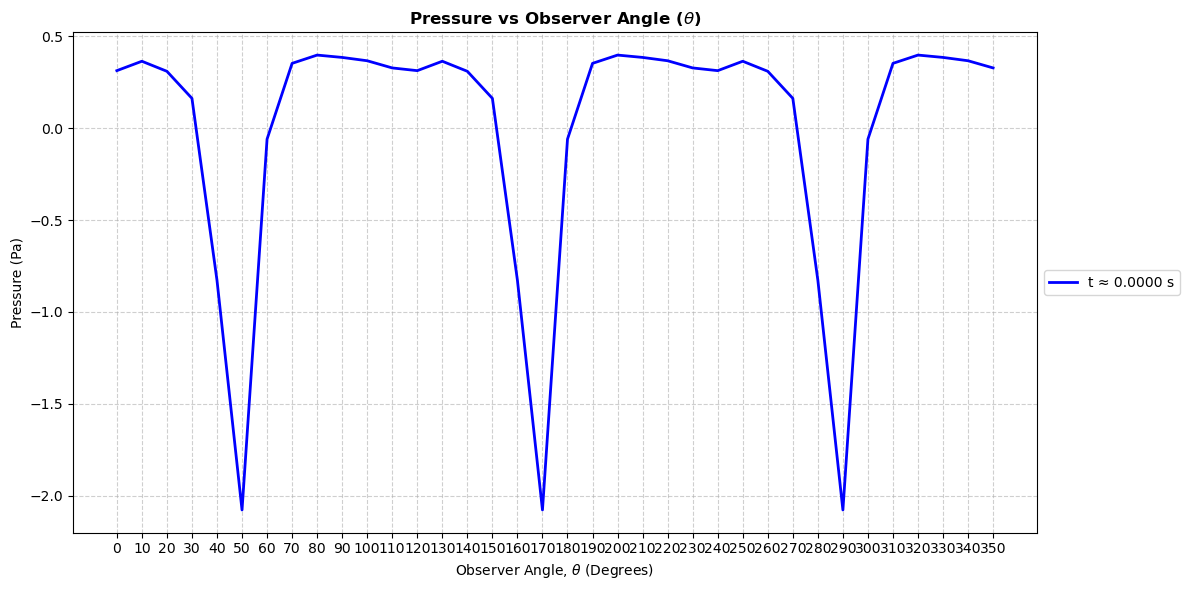

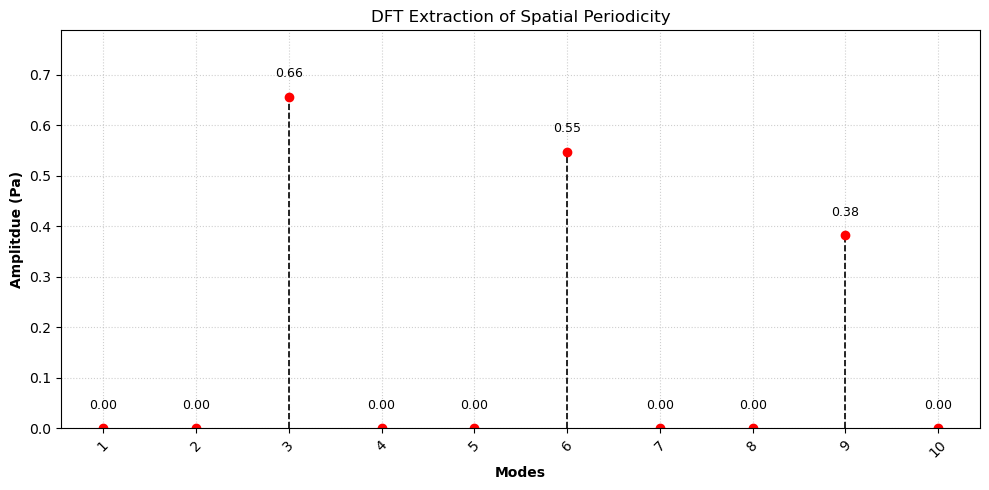

[4.90166473e-07 6.12257607e-07 6.56492366e-01 4.20856947e-07
 9.04601260e-07 5.47173375e-01 3.61727880e-07 8.26609584e-07
 3.81929807e-01 2.20333839e-07] [ 2.51316398 -1.08685693  0.69764248  1.13240404 -2.9341853  -1.85909685
  1.4475212   1.30696032  1.89662518  3.05522067]


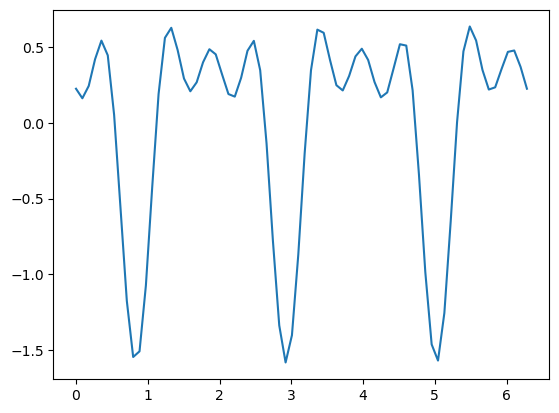

In [94]:
filepath = Path('data_260708/72Sources_12Harmonics')
obs_id = 12
temporal_data = FWHDataset(filepath=filepath / f'ana_spatial_{obs_id}.dat')
FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'3 Propeller Blade Model with 72 X 12 Stationary Monopole Sources\nTime History at Observer {obs_id}')
# fft(temporal_data, )
freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 107.25, 12)
dft_plot(freqs, amps, analysis='temporal')
obs_files = sorted(filepath.glob(f'ana_*.dat'))
datasets = [FWHDataset(filepath=f) for f in obs_files]

t_half = datasets[0].data['Time'].max() / 2
snapshot_times = np.linspace(0, datasets[0].data['Time'].max()
                                 , num=5)

angles_rad, spatial_data = FWHPlotter.plot_directivity_snapshot(datasets=datasets,
                                     target_times=0,
                                     col='P_obs',
                                     is_polar=False)

time = list(spatial_data.keys())[0]
p_theta = spatial_data[time]

modes, amps, phases = dft_spatial(angles_rad, p_theta, num_modes=10)
dft_plot(modes, amps, analysis='spatial')
print(amps, phases)

theta = np.linspace(0, 2*np.pi, 72)
pressure = 0
for i in range(len(amps)):
    amp = amps[i]
    phase = phases[i]
    mode = modes[i]
    pressure += amp * np.cos(mode * theta + phase)

fig, ax = plt.subplots()
ax.plot(theta, pressure)

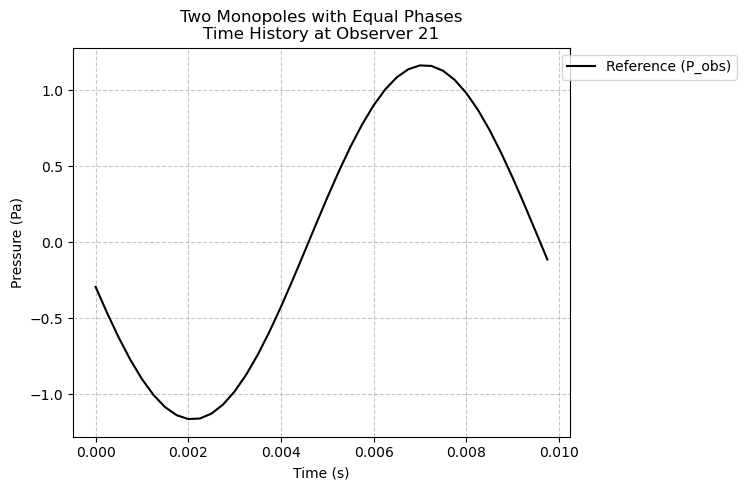

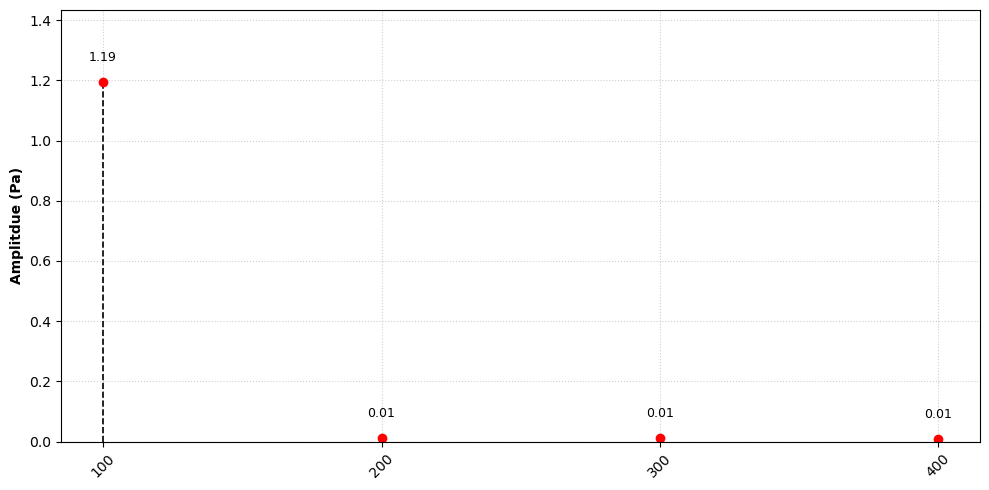

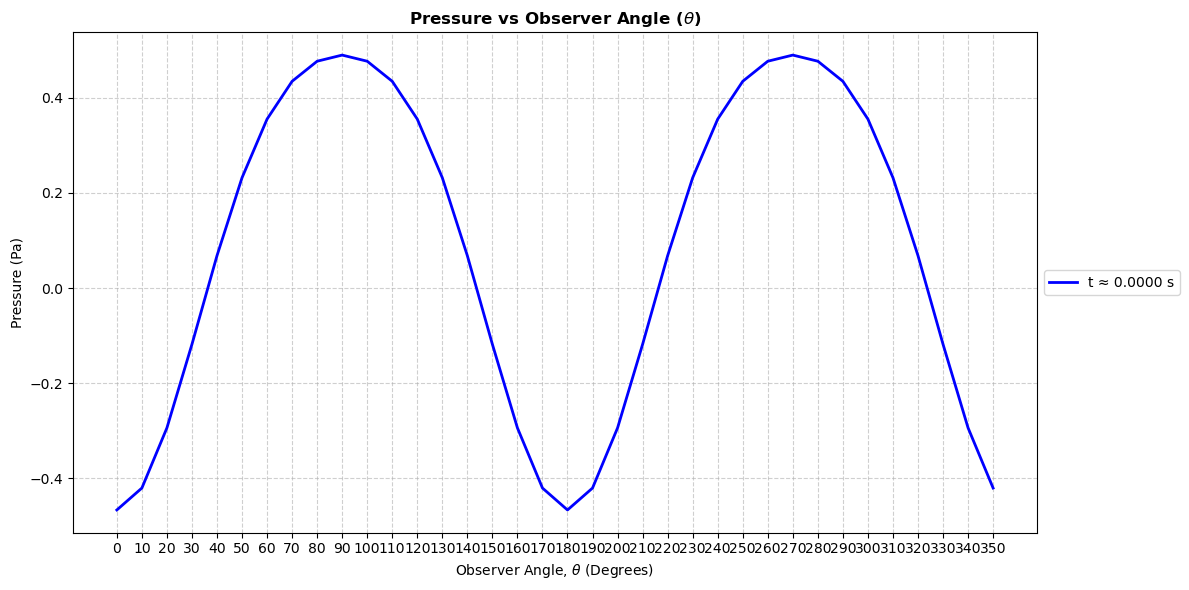

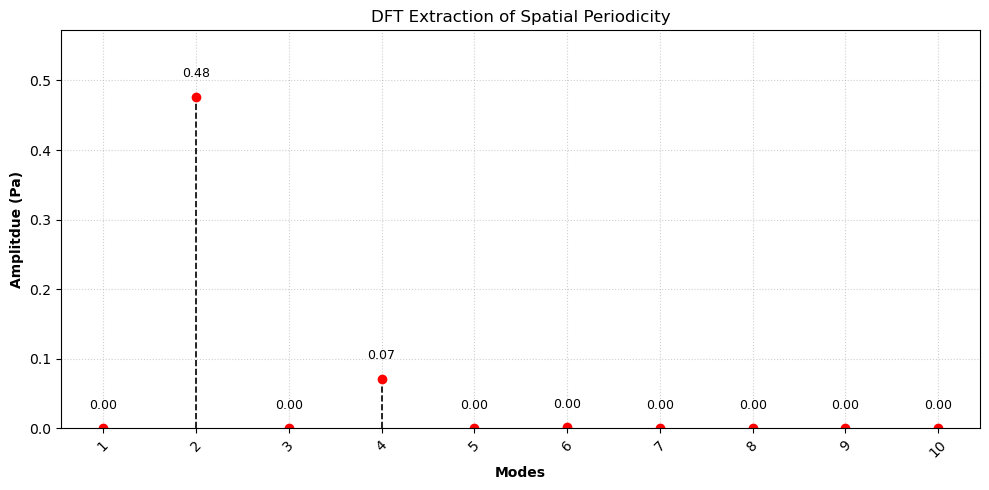

[5.36069456e-17 4.76759001e-01 1.20996657e-16 7.13719649e-02
 6.64453608e-17 1.57720789e-03 4.61193969e-17 1.20280343e-04
 1.86594235e-16 7.43020493e-06] [ 2.70558777e+00 -3.14159265e+00 -1.19706951e+00 -3.14159265e+00
 -3.74333616e-01 -3.14159265e+00 -2.85013586e+00 -4.03987937e-13
  2.88055447e-01  4.75619405e-12]


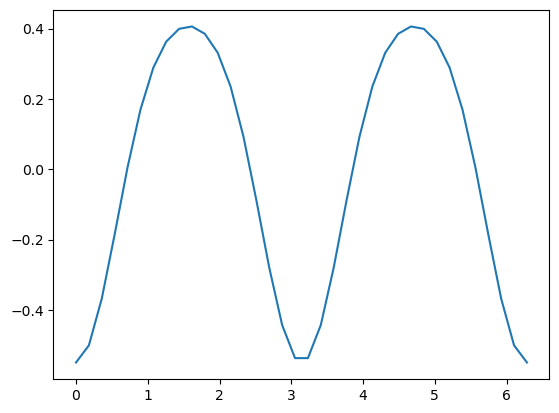

In [82]:
filepath = Path('data_260708/2lobes-0deg')
obs_id = 21
temporal_data = FWHDataset(filepath=filepath / f'ana_spatial_{obs_id}.dat')
FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'Two Monopoles with Equal Phases\nTime History at Observer {obs_id}')
# fft(temporal_data, )
freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 100, 4)
dft_plot(freqs, amps)
obs_files = sorted(filepath.glob(f'ana_*.dat'))
datasets = [FWHDataset(filepath=f) for f in obs_files]

t_half = datasets[0].data['Time'].max() / 2
snapshot_times = np.linspace(0, datasets[0].data['Time'].max()
                                 , num=5)

angles_rad, spatial_data = FWHPlotter.plot_directivity_snapshot(datasets=datasets,
                                     target_times=0,
                                     col='P_obs',
                                     is_polar=False)

time = list(spatial_data.keys())[0]
p_theta = spatial_data[time]

modes, amps, phases = dft_spatial(angles_rad, p_theta, num_modes=10)
dft_plot(modes, amps, analysis='spatial')
print(amps, phases)

theta = np.linspace(0, 2*np.pi, 36)
pressure = 0
for i in range(len(amps)):
    amp = amps[i]
    phase = phases[i]
    mode = modes[i]
    pressure += amp * np.cos(mode * theta + phase)

fig, ax = plt.subplots()
ax.plot(theta, pressure)

<>:4: SyntaxWarning: invalid escape sequence '\p'
<>:4: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_482462/1183322132.py:4: SyntaxWarning: invalid escape sequence '\p'
  FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'Two Monopoles with Phase Angles $\phi$=90$^\circ$, 270$^\circ$\nTime History at Observer {obs_id}')


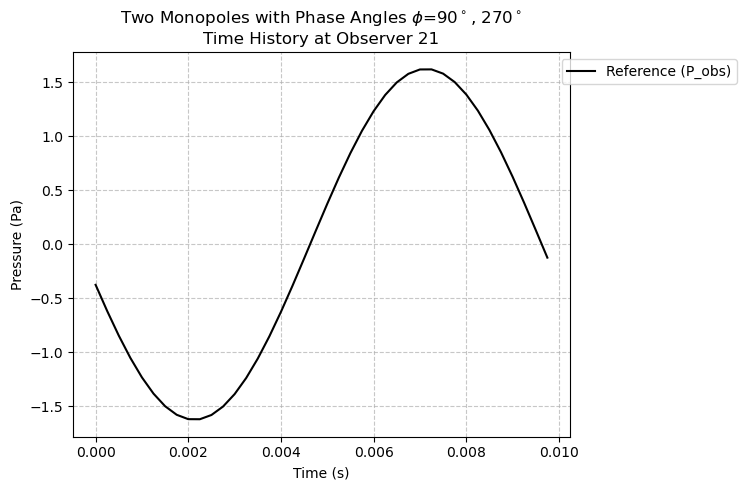

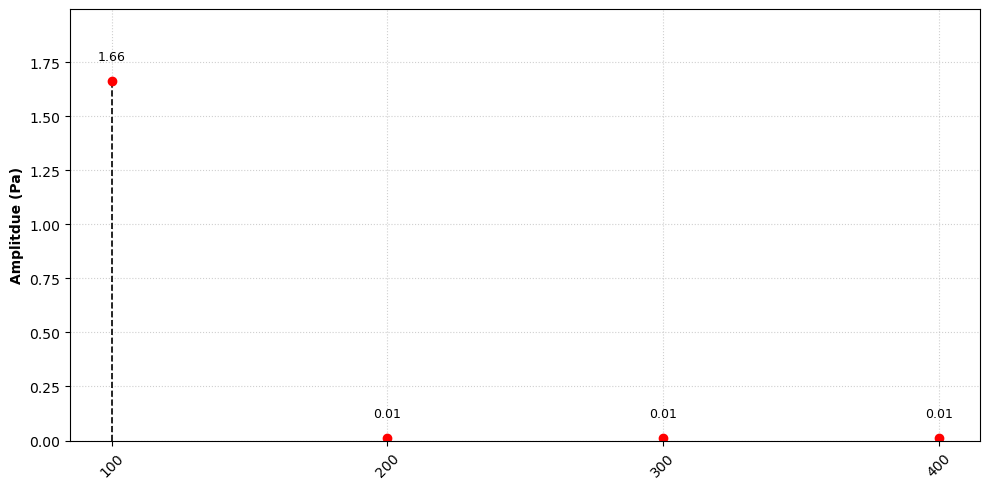

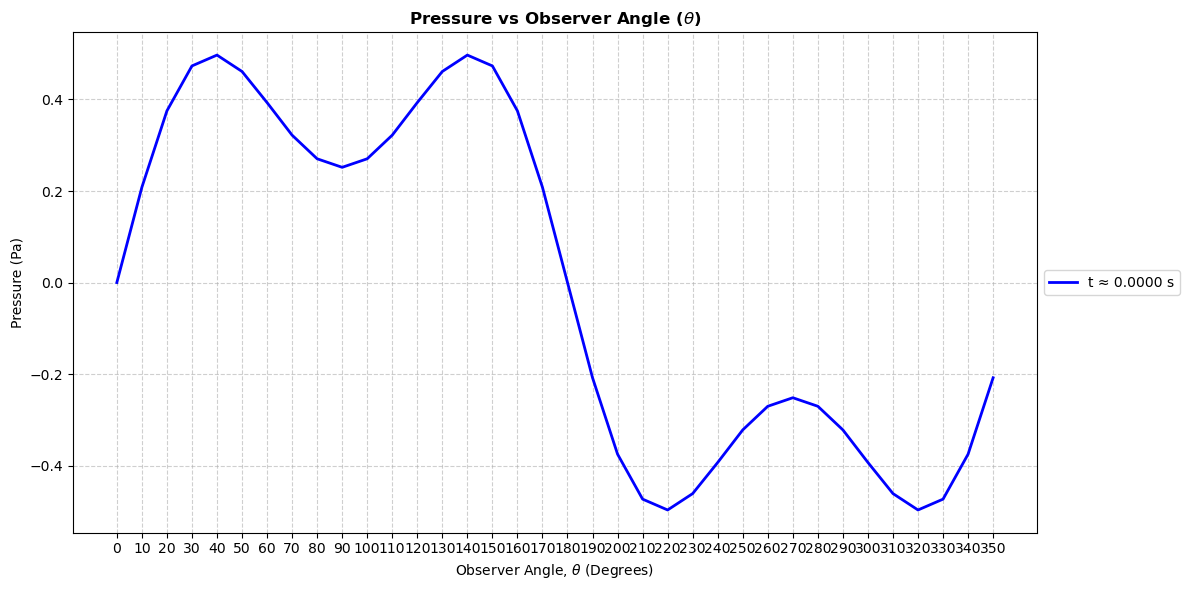

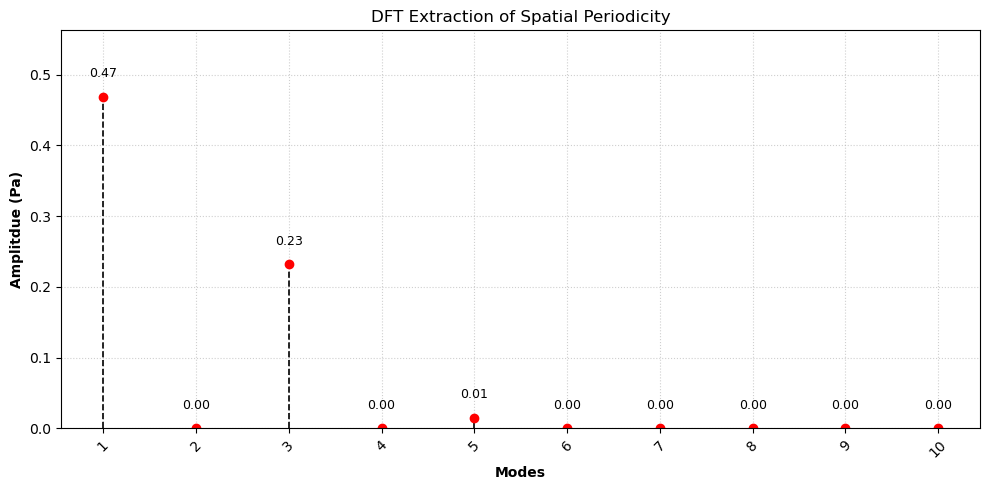

[4.68717139e-01 8.06888221e-08 2.31601089e-01 1.12984220e-08
 1.45306884e-02 4.62824926e-10 1.43162978e-04 4.95441379e-09
 3.55238889e-05 1.17125061e-09] [-1.57079633e+00  3.14159265e+00 -1.57079633e+00  3.14159265e+00
 -1.57079633e+00  5.96531864e-08  1.57079633e+00  3.14159264e+00
  1.57079633e+00 -6.69451156e-08]


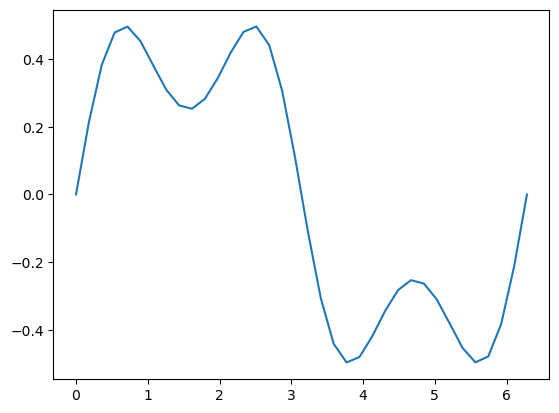

In [81]:
filepath = Path('data_260708/2lobes-180deg')
obs_id = 21
temporal_data = FWHDataset(filepath=filepath / f'ana_spatial_{obs_id}.dat')
FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'Two Monopoles with Phase Angles $\phi$=90$^\circ$, 270$^\circ$\nTime History at Observer {obs_id}')
# fft(temporal_data, )
freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 100, 4)
dft_plot(freqs, amps)
obs_files = sorted(filepath.glob(f'ana_*.dat'))
datasets = [FWHDataset(filepath=f) for f in obs_files]

t_half = datasets[0].data['Time'].max() / 2
snapshot_times = np.linspace(0, datasets[0].data['Time'].max()
                                 , num=5)

angles_rad, spatial_data = FWHPlotter.plot_directivity_snapshot(datasets=datasets,
                                     target_times=0,
                                     col='P_obs',
                                     is_polar=False)

time = list(spatial_data.keys())[0]
p_theta = spatial_data[time]

modes, amps, phases = dft_spatial(angles_rad, p_theta, num_modes=10)
dft_plot(modes, amps, analysis='spatial')
print(amps, phases)

theta = np.linspace(0, 2*np.pi, 36)
pressure = 0
for i in range(len(amps)):
    amp = amps[i]
    phase = phases[i]
    mode = modes[i]
    pressure += amp * np.cos(mode * theta + phase)

fig, ax = plt.subplots()
ax.plot(theta, pressure)

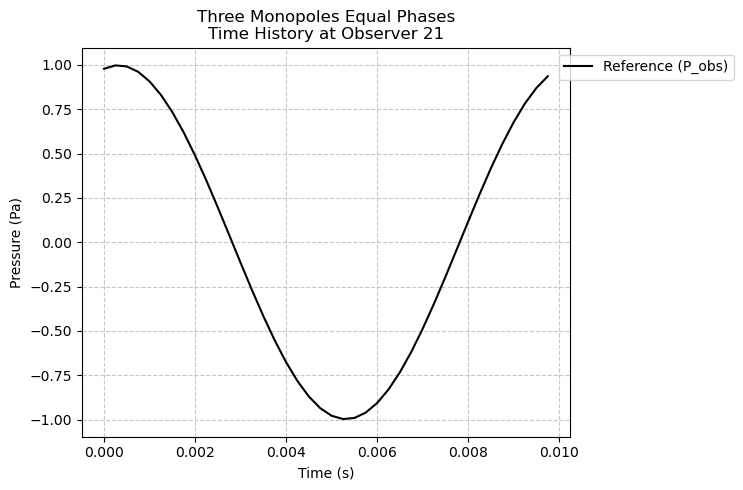

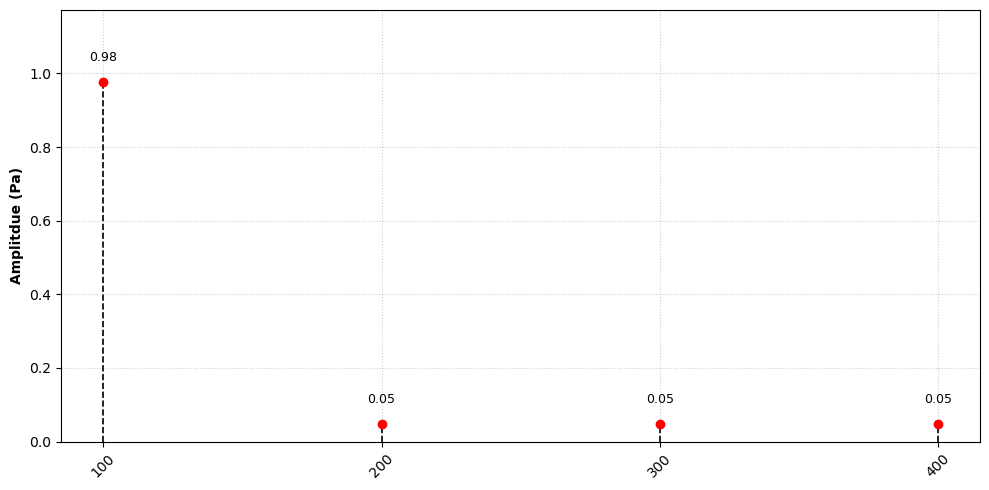

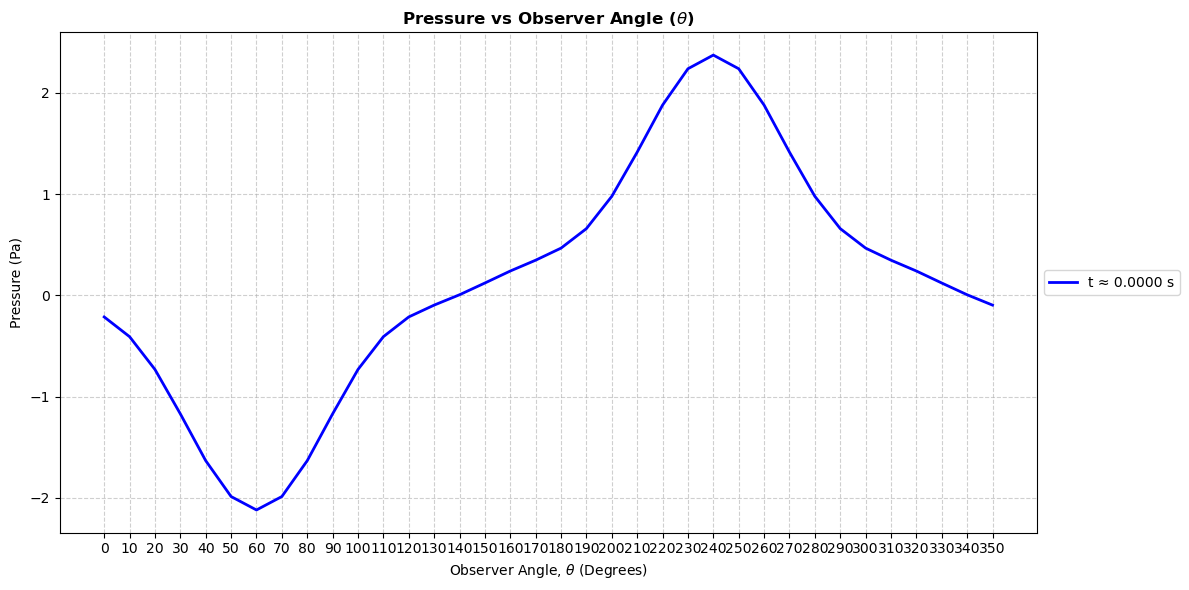

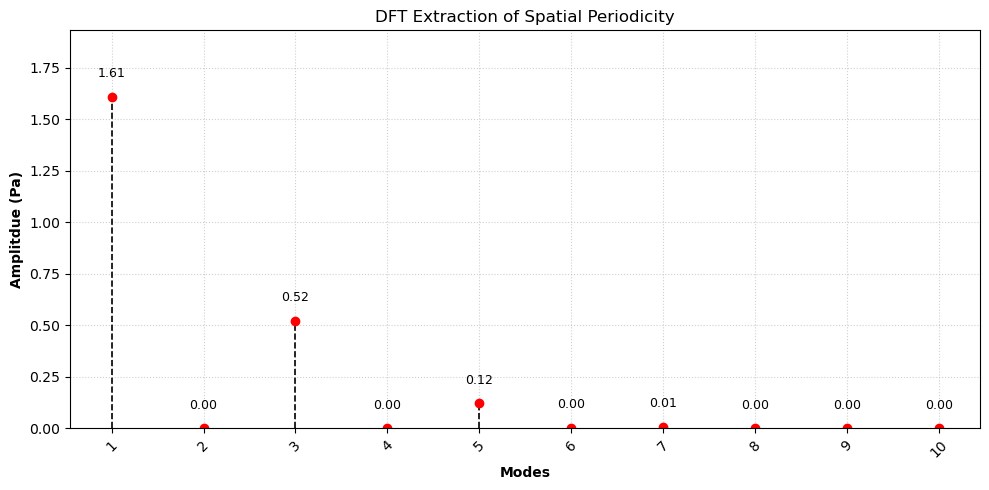

[1.60930828e+00 2.04680184e-08 5.22622270e-01 3.14130335e-07
 1.22097838e-01 2.36656263e-03 6.12261755e-03 2.95703943e-08
 8.40778030e-05 1.64561802e-08] [ 2.09439503e+00  5.33540484e-02 -4.59911678e-07  3.12170574e+00
 -2.09439623e+00 -1.98015455e-06 -1.04718878e+00 -1.06042321e-01
 -3.14132504e+00  2.05979312e+00]


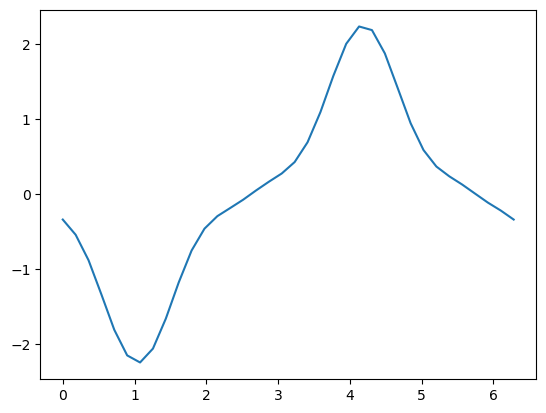

In [87]:
filepath = Path('data_260708/3lobes-0deg')
obs_id = 21
temporal_data = FWHDataset(filepath=filepath / f'ana_spatial_{obs_id}.dat')
FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'Three Monopoles Equal Phases\nTime History at Observer {obs_id}')
# fft(temporal_data, )
freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 100, 4)
dft_plot(freqs, amps)
obs_files = sorted(filepath.glob(f'ana_*.dat'))
datasets = [FWHDataset(filepath=f) for f in obs_files]

t_half = datasets[0].data['Time'].max() / 2
snapshot_times = np.linspace(0, datasets[0].data['Time'].max()
                                 , num=5)

angles_rad, spatial_data = FWHPlotter.plot_directivity_snapshot(datasets=datasets,
                                     target_times=0,
                                     col='P_obs',
                                     is_polar=False)

time = list(spatial_data.keys())[0]
p_theta = spatial_data[time]

modes, amps, phases = dft_spatial(angles_rad, p_theta, num_modes=10)
dft_plot(modes, amps, analysis='spatial')
print(amps, phases)


theta = np.linspace(0, 2*np.pi, 36)
pressure = 0
for i in range(len(amps)):
    amp = amps[i]
    phase = phases[i]
    mode = modes[i]
    pressure += amp * np.cos(mode * theta + phase)

fig, ax = plt.subplots()
ax.plot(theta, pressure)

<>:4: SyntaxWarning: invalid escape sequence '\p'
<>:4: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_482462/2979589544.py:4: SyntaxWarning: invalid escape sequence '\p'
  FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'Three Monopoles with Phase Angles $\phi$=0$^\circ$, 120$^\circ$, 240$^\circ$\nTime History at Observer {obs_id}')


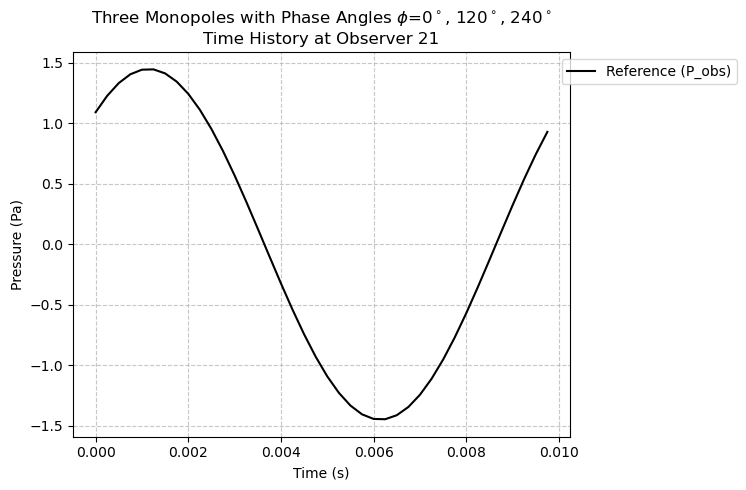

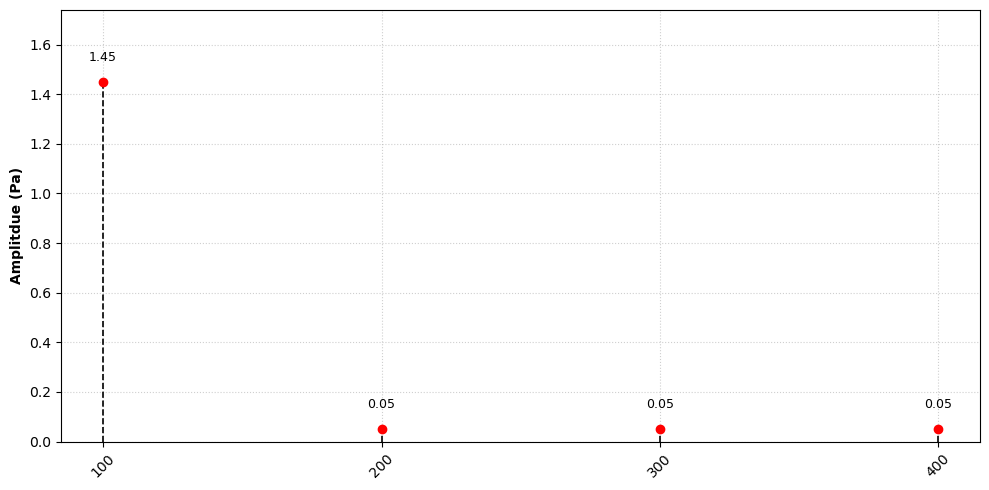

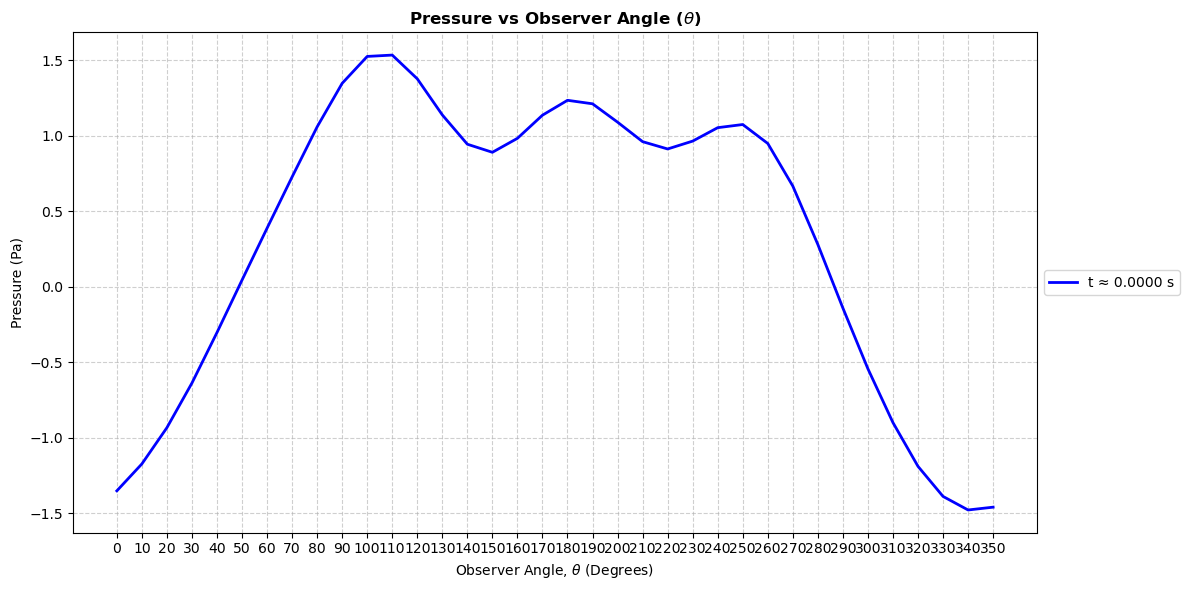

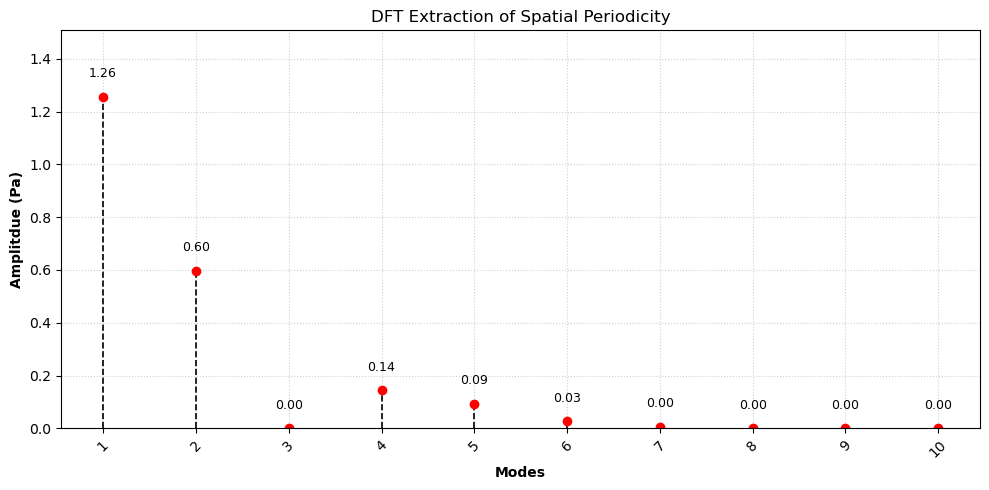

[1.25713253e+00 5.96432419e-01 4.27086952e-07 1.44092237e-01
 9.22197934e-02 2.65839592e-02 4.59322884e-03 5.32344671e-04
 7.20837131e-08 1.40711615e-05] [-2.85817880e+00 -2.78814952e+00 -1.00301677e+00 -2.16159196e-01
  3.02313270e+00  1.07721251e-05 -2.33053540e-02 -9.77367841e-02
 -1.41603754e+00 -2.90584580e+00]


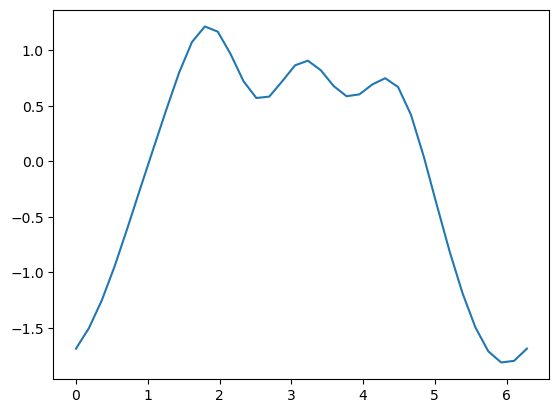

In [84]:
filepath = Path('data_260708/3lobes-120deg')
obs_id = 21
temporal_data = FWHDataset(filepath=filepath / f'ana_spatial_{obs_id}.dat')
FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'Three Monopoles with Phase Angles $\phi$=0$^\circ$, 120$^\circ$, 240$^\circ$\nTime History at Observer {obs_id}')
# fft(temporal_data, )
freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 100, 4)
dft_plot(freqs, amps)
obs_files = sorted(filepath.glob(f'ana_*.dat'))
datasets = [FWHDataset(filepath=f) for f in obs_files]

t_half = datasets[0].data['Time'].max() / 2
snapshot_times = np.linspace(0, datasets[0].data['Time'].max()
                                 , num=5)

angles_rad, spatial_data = FWHPlotter.plot_directivity_snapshot(datasets=datasets,
                                     target_times=0,
                                     col='P_obs',
                                     is_polar=False)

time = list(spatial_data.keys())[0]
p_theta = spatial_data[time]

modes, amps, phases = dft_spatial(angles_rad, p_theta, num_modes=10)
dft_plot(modes, amps, analysis='spatial')
print(amps, phases)

theta = np.linspace(0, 2*np.pi, 36)
pressure = 0
for i in range(len(amps)):
    amp = amps[i]
    phase = phases[i]
    mode = modes[i]
    pressure += amp * np.cos(mode * theta + phase)

fig, ax = plt.subplots()
ax.plot(theta, pressure)

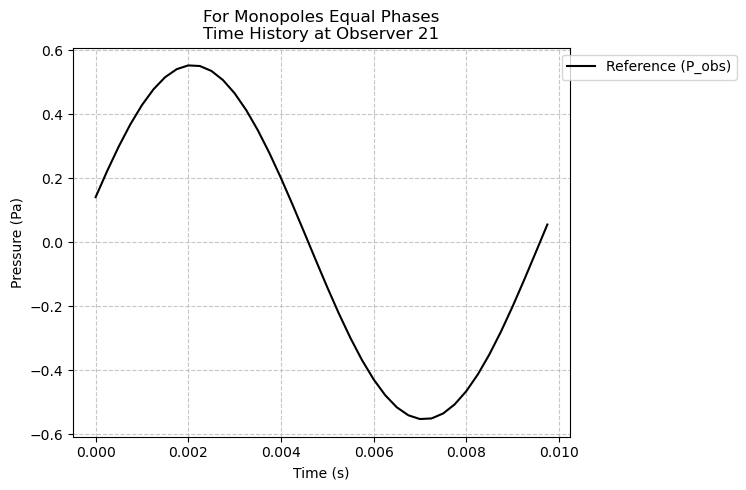

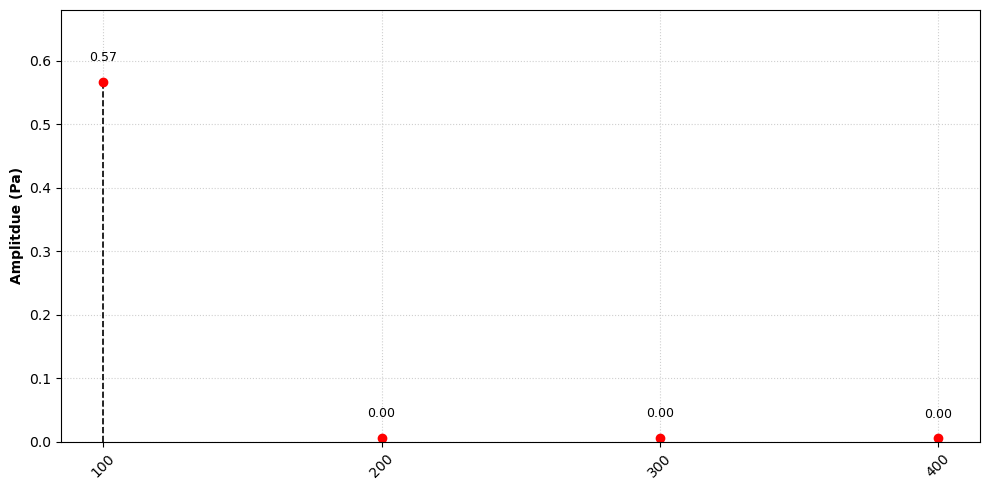

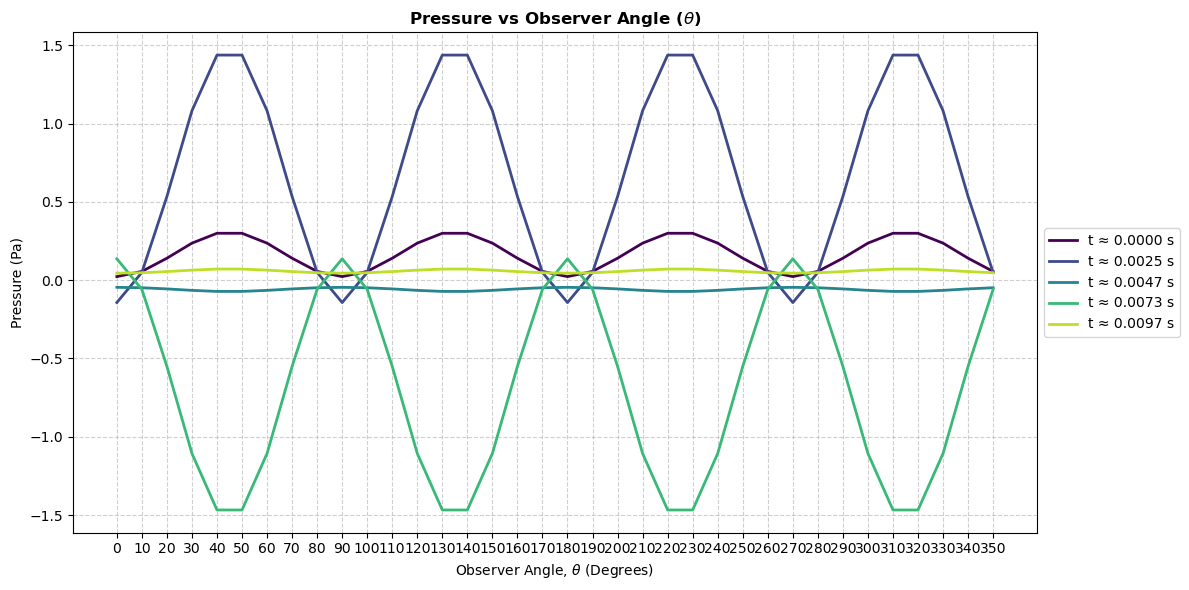

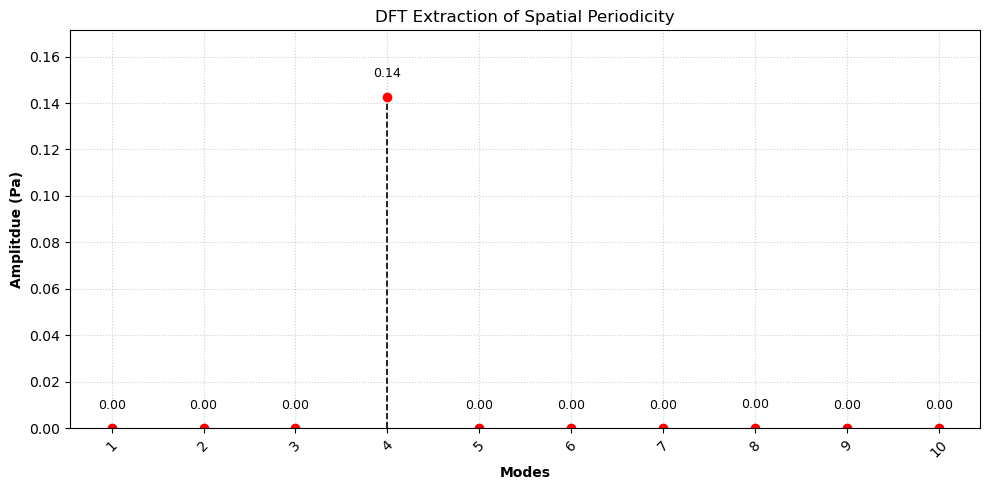

[3.20750433e-17 1.95634524e-17 1.03779294e-16 1.42743928e-01
 8.06277991e-17 9.70085484e-17 4.33469804e-17 2.40550678e-04
 4.46832837e-17 8.56182297e-17] [-2.81405788e+00 -2.98572445e+00 -2.13813766e+00 -3.14159265e+00
  1.54097391e-02 -7.24987887e-01 -2.33817842e+00 -1.19365038e-13
  1.67292424e+00  8.54999838e-01]


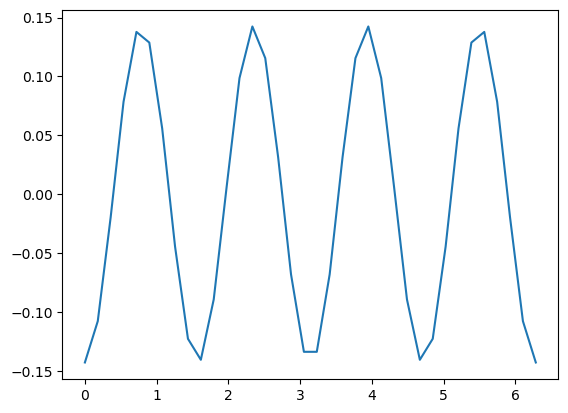

In [85]:
filepath = Path('data_260708/4lobes-0deg')
obs_id = 21
temporal_data = FWHDataset(filepath=filepath / f'ana_spatial_{obs_id}.dat')
FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'For Monopoles Equal Phases\nTime History at Observer {obs_id}')
# fft(temporal_data, )
freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 100, 4)
dft_plot(freqs, amps)
obs_files = sorted(filepath.glob(f'ana_*.dat'))
datasets = [FWHDataset(filepath=f) for f in obs_files]

t_half = datasets[0].data['Time'].max() / 2
snapshot_times = np.linspace(0, datasets[0].data['Time'].max()
                                 , num=5)

angles_rad, spatial_data = FWHPlotter.plot_directivity_snapshot(datasets=datasets,
                                     target_times=snapshot_times,
                                     col='P_obs',
                                     is_polar=False)

time = list(spatial_data.keys())[0]
p_theta = spatial_data[time]

modes, amps, phases = dft_spatial(angles_rad, p_theta, num_modes=10)
dft_plot(modes, amps, analysis='spatial')
print(amps, phases)

theta = np.linspace(0, 2*np.pi, 36)
pressure = 0
for i in range(len(amps)):
    amp = amps[i]
    phase = phases[i]
    mode = modes[i]
    pressure += amp * np.cos(mode * theta + phase)

fig, ax = plt.subplots()
ax.plot(theta, pressure)

<>:4: SyntaxWarning: invalid escape sequence '\p'
<>:4: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_482462/4264441259.py:4: SyntaxWarning: invalid escape sequence '\p'
  FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'Four Monopoles with Phase Angles $\phi$=0$^\circ$, 90$^\circ$, 180$^\circ$ 270$^\circ$\nTime History at Observer {obs_id}')


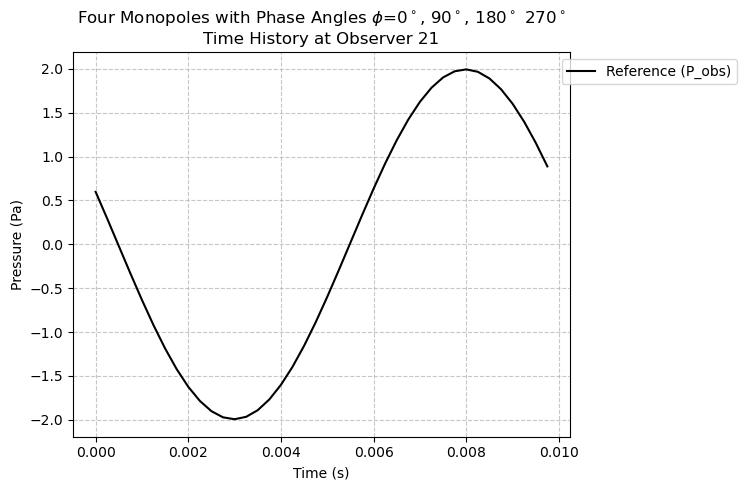

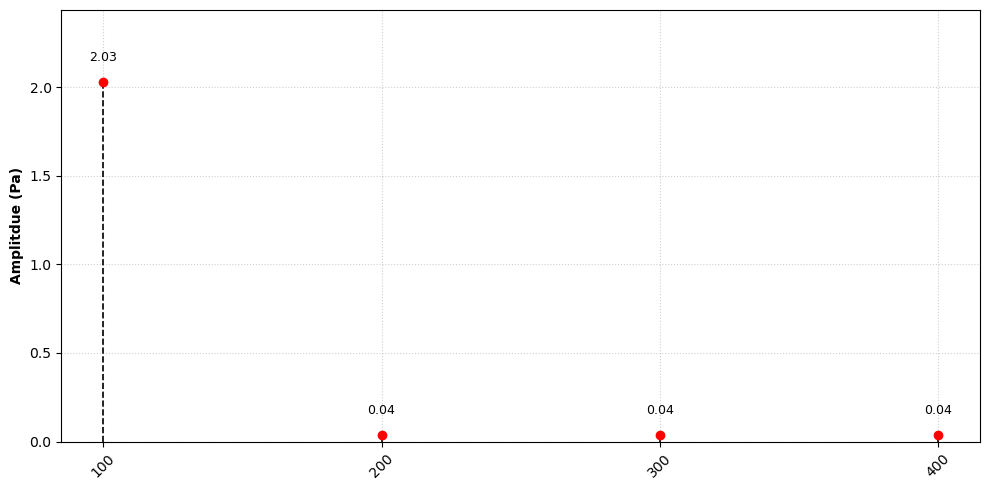

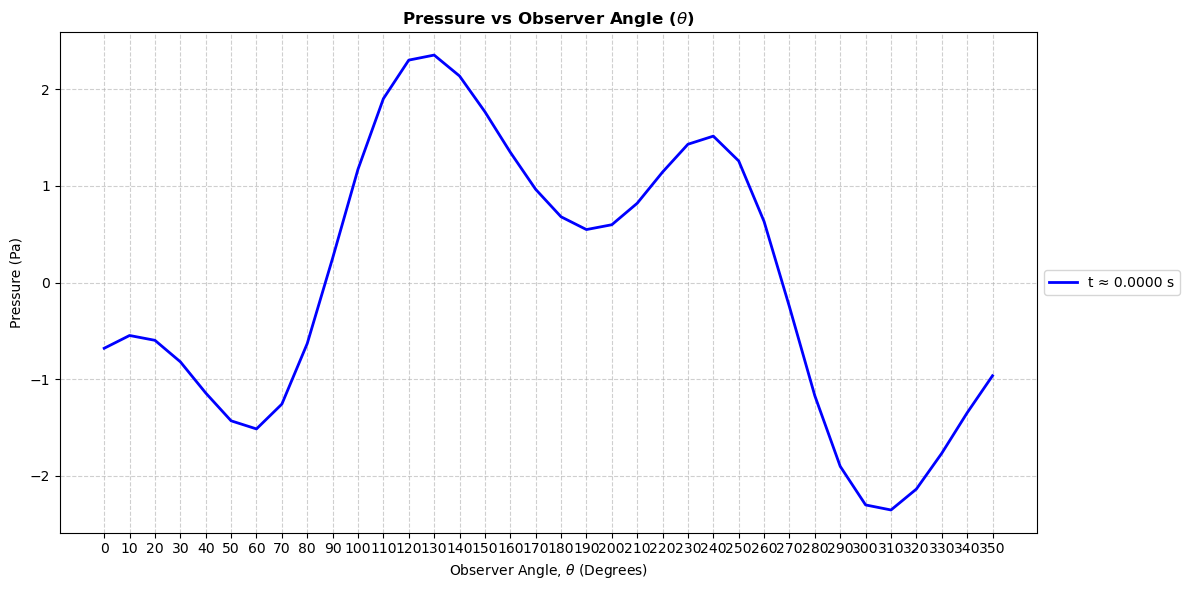

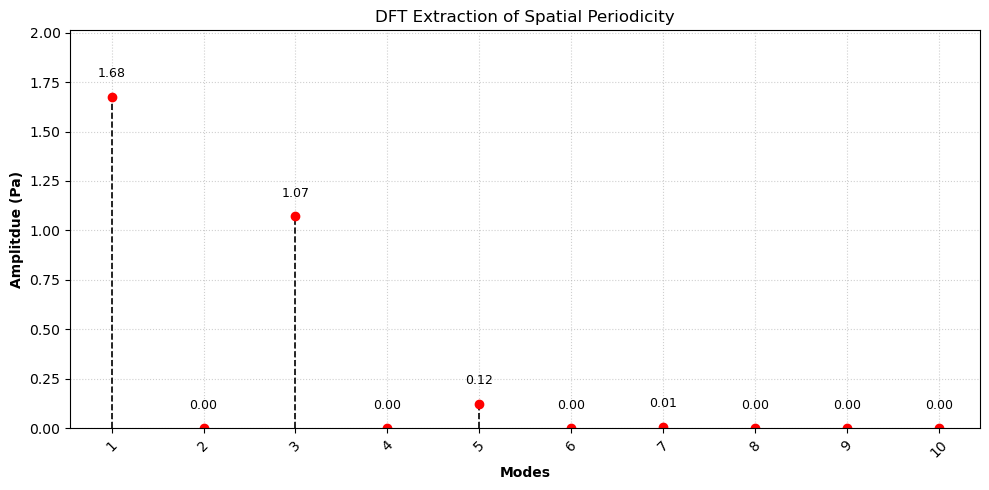

[1.67617662e+00 4.05465440e-07 1.07059569e+00 5.54125801e-08
 1.22959666e-01 1.25092558e-08 6.12438294e-03 3.83996175e-09
 1.71878073e-04 3.46707046e-09] [-2.85817905 -3.12485724 -0.21805305 -0.1784896  -3.02314133  2.6179939
  0.02337989 -1.22054307  2.93343454 -1.59886456]


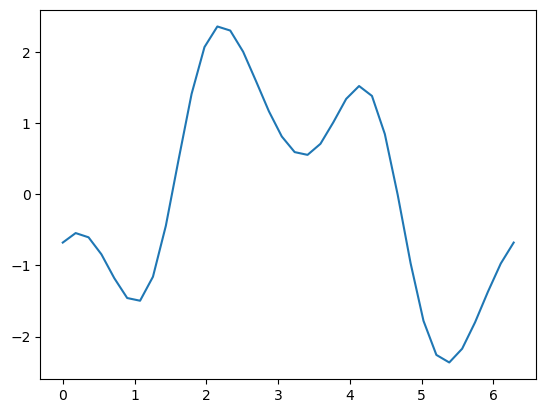

In [86]:
filepath = Path('data_260708/4lobes-90deg')
obs_id = 21
temporal_data = FWHDataset(filepath=filepath / f'ana_spatial_{obs_id}.dat')
FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title=f'Four Monopoles with Phase Angles $\phi$=0$^\circ$, 90$^\circ$, 180$^\circ$ 270$^\circ$\nTime History at Observer {obs_id}')
# fft(temporal_data, )
freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 100, 4)
dft_plot(freqs, amps)
obs_files = sorted(filepath.glob(f'ana_*.dat'))
datasets = [FWHDataset(filepath=f) for f in obs_files]

angles_rad, spatial_data = FWHPlotter.plot_directivity_snapshot(datasets=datasets,
                                     target_times=0,
                                     col='P_obs',
                                     is_polar=False)

time = list(spatial_data.keys())[0]
p_theta = spatial_data[time]

modes, amps, phases = dft_spatial(angles_rad, p_theta, num_modes=10)
dft_plot(modes, amps, analysis='spatial')
print(amps, phases)

theta = np.linspace(0, 2*np.pi, 36)
pressure = 0
for i in range(len(amps)):
    amp = amps[i]
    phase = phases[i]
    mode = modes[i]
    pressure += amp * np.cos(mode * theta + phase)

fig, ax = plt.subplots()
ax.plot(theta, pressure)

In [ ]:
# filepath = Path('data_260707/4lobes-Test')
# temporal_data = FWHDataset(filepath=filepath / 'ana_spatial_21.dat')
# FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title='Validation Data using Analytical Model of Decomposed Data')
# # fft(temporal_data, )
# freqs, amps, phases = dft(temporal_data.data['Time'], temporal_data.data['P_obs'], 100, 4)
# dft_plot(freqs, amps)
# obs_files = sorted(filepath.glob(f'ana_*.dat'))# datasets = [FWHDataset(filepath=f) for f in obs_files]

# FWHPlotter.plot_directivity_snapshot(datasets=datasets,
#                                      target_times=7e-3,
#                                      col='P_obs',
#                                      is_polar=False)